# Olist: Onde investir para continuar crescendo
### Tech Challenge – Fase 1 · POSTECH Data Analytics (FIAP)

**Autora:** Sthephany Nascimento **RM:** 377624

**Pergunta norteadora:** *O crescimento da Olist vai continuar? E onde vale mais a pena investir para isso acontecer?*

**Por que é importante:** o investidor precisa saber se o crescimento se mantém sozinho ou depende de investimento, e onde esse investimento traz mais retorno.

**Base:** *Brazilian E-Commerce Public Dataset by Olist* (Kaggle), cerca de 100 mil pedidos reais e anonimizados, de set/2016 a out/2018.

### Metodologia: CRISP-DM


## Sumário executivo

1. **Crescimento forte, mas desacelerando.** A receita de jan–ago/2018 foi **2,4 vezes** a do mesmo período de 2017, bem acima do e-commerce brasileiro (+12% em 2018). Porém, desde jan/2018 o volume estabilizou em torno de 6,5 a 7 mil pedidos por mês.
2. **A entrega é o que define a nota do cliente.** Pedidos entregues no prazo recebem nota média **4,3**; pedidos atrasados, **2,3**. Entre os atrasados, **6 em cada 10** recebem nota 1 ou 2.
3. **A operação não aguenta os picos.** Depois da Black Friday de 2017 e no 1º trimestre de 2018, a taxa de atraso subiu de cerca de 4% para até **19%**.
4. **O Norte e o Nordeste são mercado mal atendido.** Lá o cliente espera o dobro do tempo do paulista (cerca de 20 dias contra 9) e paga frete proporcionalmente 50% a 70% mais caro, mesmo com ticket médio maior.
5. **Quase ninguém volta a comprar.** Só **3%** dos clientes fizeram mais de um pedido, então o crescimento depende de conquistar novos clientes o tempo todo.

**Recomendação central:** investir em **logística regional e capacidade para picos**, e criar um **programa de recompra**. Detalhes na seção 11.

## 1. Preparação do ambiente e carregamento dos dados

**Como rodar:** no Colab, clique em *Ambiente de execução → Executar tudo* e, quando pedir, envie o arquivo `archive.zip` baixado do Kaggle ([link do dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)).

In [1]:
# Bibliotecas para lidar com arquivos e com o .zip
import os
import zipfile

# Pasta onde ficam os arquivos CSV do Kaggle
DATA_DIR = 'data'

# Se a pasta data/ ainda não tem os arquivos, pedimos o archive.zip (no Colab) e extraímos
if not os.path.exists(DATA_DIR + '/olist_orders_dataset.csv'):
    from google.colab import files
    print('Selecione o arquivo archive.zip baixado do Kaggle')
    arquivo = files.upload()
    nome_zip = list(arquivo.keys())[0]
    zipfile.ZipFile(nome_zip).extractall(DATA_DIR)

# Mostra os arquivos disponíveis
print(os.listdir(DATA_DIR))

['olist_order_reviews_dataset.csv', 'olist_order_items_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_sellers_dataset.csv', 'olist_products_dataset.csv', 'olist_customers_dataset.csv', 'olist_orders_dataset.csv', 'product_category_name_translation.csv', 'olist_order_payments_dataset.csv']


In [2]:
# Bibliotecas de análise e de gráficos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cores usadas nos gráficos: azul para o normal, laranja para destacar problemas
AZUL = '#2a78d6'
LARANJA = '#eb6834'
CINZA = '#9a9893'

# Tamanho padrão dos gráficos e remoção das bordas de cima e da direita
plt.rcParams['figure.figsize'] = (10, 4.8)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Pasta para salvar os gráficos (usados depois nos slides)
os.makedirs('figuras', exist_ok=True)

In [3]:
# Colunas de data da tabela de pedidos (para o pandas ler como data, e não como texto)
colunas_data = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
                'order_delivered_customer_date', 'order_estimated_delivery_date']

# Leitura das tabelas
pedidos    = pd.read_csv(DATA_DIR + '/olist_orders_dataset.csv', parse_dates=colunas_data)
clientes   = pd.read_csv(DATA_DIR + '/olist_customers_dataset.csv')
itens      = pd.read_csv(DATA_DIR + '/olist_order_items_dataset.csv')
produtos   = pd.read_csv(DATA_DIR + '/olist_products_dataset.csv')
avaliacoes = pd.read_csv(DATA_DIR + '/olist_order_reviews_dataset.csv')
pagamentos = pd.read_csv(DATA_DIR + '/olist_order_payments_dataset.csv')
vendedores = pd.read_csv(DATA_DIR + '/olist_sellers_dataset.csv')

# Tamanho de cada tabela e % de valores vazios
for nome, tabela in [('pedidos', pedidos), ('clientes', clientes), ('itens', itens),
                     ('produtos', produtos), ('avaliacoes', avaliacoes),
                     ('pagamentos', pagamentos), ('vendedores', vendedores)]:
    vazios = tabela.isna().mean().mean() * 100
    print(f'{nome}: {tabela.shape[0]} linhas, {tabela.shape[1]} colunas, {vazios:.1f}% vazios')

pedidos: 99441 linhas, 8 colunas, 0.6% vazios
clientes: 99441 linhas, 5 colunas, 0.0% vazios
itens: 112650 linhas, 7 colunas, 0.0% vazios
produtos: 32951 linhas, 9 colunas, 0.8% vazios
avaliacoes: 99224 linhas, 7 colunas, 21.0% vazios
pagamentos: 103886 linhas, 5 colunas, 0.0% vazios
vendedores: 3095 linhas, 4 colunas, 0.0% vazios


### Como as tabelas se conectam (fato e dimensão)

Separei as tabelas em dois tipos: as **fato**, que registram o que aconteceu (vendas, pagamentos e avaliações), e as **dimensão**, que descrevem quem comprou, o que foi comprado e quem vendeu.

| Tabela | Tipo | O que tem | Se liga por |
|---|---|---|---|
| `order_items` | Fato | Preço e frete de cada item vendido | `order_id`, `product_id`, `seller_id` |
| `order_payments` | Fato | Forma de pagamento e parcelas | `order_id` |
| `order_reviews` | Fato | Nota do cliente (1 a 5) | `order_id` |
| `orders` | Fato | Status e datas do pedido | `order_id`, `customer_id` |
| `customers` | Dimensão | Cidade e estado do cliente | `customer_id` |
| `products` | Dimensão | Categoria do produto | `product_id` |
| `sellers` | Dimensão | Cidade e estado do vendedor | `seller_id` |

A tabela que liga tudo é a `orders`: pelo `order_id` chego nos itens, pagamentos e avaliações, e pelo `customer_id` chego no cliente.

## 2. Qualidade dos dados (governança)

Antes de começar a análise, conferi se dava para confiar nos dados e escolhi o período que ia usar.

- **Campos vazios:** aparecem onde já era esperado, como a data de entrega de pedidos que ainda não chegaram e os comentários das avaliações (que o cliente não é obrigado a escrever). A tabela de geolocalização não entrou na análise.
- **Status:** 97% dos pedidos foram entregues.
- **Período:** os meses do fim de 2016 e de set–out/2018 têm pouquíssimos pedidos (é o começo e o fim da coleta). Por isso, nas análises por mês, usei só de **jan/2017 a ago/2018**.

In [4]:
# Período coberto pelos dados
print('Primeiro pedido:', pedidos['order_purchase_timestamp'].min())
print('Último pedido:', pedidos['order_purchase_timestamp'].max())

# Status dos pedidos (em %)
print()
print(pedidos['order_status'].value_counts(normalize=True) * 100)

# Quantidade de pedidos por mês: os meses das pontas têm pouquíssimos pedidos
print()
pedidos_mes = pedidos['order_purchase_timestamp'].dt.to_period('M').value_counts().sort_index()
print(pedidos_mes)

Primeiro pedido: 2016-09-04 21:15:19
Último pedido: 2018-10-17 17:30:18

order_status
delivered      97.020344
shipped         1.113223
canceled        0.628513
unavailable     0.612423
invoiced        0.315765
processing      0.302692
created         0.005028
approved        0.002011
Name: proportion, dtype: float64

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64


In [5]:
# 1) Valor de cada pedido: soma dos preços e dos fretes dos itens
valor_pedido = itens.groupby('order_id').agg(receita=('price', 'sum'), frete=('freight_value', 'sum'))

# 2) Tiramos pedidos cancelados ou indisponíveis
pedidos_validos = pedidos[~pedidos['order_status'].isin(['canceled', 'unavailable'])]

# 3) Juntamos pedidos + valores + dados do cliente
vendas = pedidos_validos.merge(valor_pedido, on='order_id')
vendas = vendas.merge(clientes, on='customer_id')

# 4) Criamos a coluna de mês e mantemos só jan/2017 a ago/2018
vendas['mes'] = vendas['order_purchase_timestamp'].dt.to_period('M')
vendas = vendas[(vendas['mes'] >= '2017-01') & (vendas['mes'] <= '2018-08')]

# 5) Região de cada estado
REGIAO = {
    'SP': 'Sudeste', 'RJ': 'Sudeste', 'MG': 'Sudeste', 'ES': 'Sudeste',
    'PR': 'Sul', 'SC': 'Sul', 'RS': 'Sul',
    'DF': 'Centro-Oeste', 'GO': 'Centro-Oeste', 'MT': 'Centro-Oeste', 'MS': 'Centro-Oeste',
    'AC': 'Norte', 'AP': 'Norte', 'AM': 'Norte', 'PA': 'Norte', 'RO': 'Norte', 'RR': 'Norte', 'TO': 'Norte',
    'MA': 'Nordeste', 'PI': 'Nordeste', 'CE': 'Nordeste', 'RN': 'Nordeste', 'PB': 'Nordeste',
    'PE': 'Nordeste', 'AL': 'Nordeste', 'SE': 'Nordeste', 'BA': 'Nordeste',
}
vendas['regiao'] = vendas['customer_state'].map(REGIAO)

print('Pedidos válidos:', len(vendas))
print(f'Receita total: R$ {vendas["receita"].sum():,.2f}')

Pedidos válidos: 97905
Receita total: R$ 13,449,529.68


### Estatística descritiva e outliers

Calculei a média, a mediana e a moda para entender o valor mais comum dos pedidos e do frete. Também calculei o desvio-padrão, a amplitude e o coeficiente de variação para ver o quanto esses valores mudam de um pedido para outro.

Os outliers são os pedidos com valor muito acima do normal. Considerei outlier tudo que passa de Q3 + 1,5 × IQR.

In [6]:
# Medidas de tendência central e de dispersão para o valor e o frete dos pedidos
for coluna in ['receita', 'frete']:
    serie = vendas[coluna]

    # Outliers pelo método IQR: acima de Q3 + 1,5 x (Q3 - Q1)
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    limite = q3 + 1.5 * (q3 - q1)
    pct_outliers = (serie > limite).mean() * 100

    print(f'--- {coluna} ---')
    print(f'Média: R$ {serie.mean():.2f} | Mediana: R$ {serie.median():.2f} | Moda: R$ {serie.round().mode()[0]:.0f}')
    print(f'Desvio-padrão: R$ {serie.std():.2f} | Mínimo: R$ {serie.min():.2f} | Máximo: R$ {serie.max():.2f}')
    print(f'Coeficiente de variação: {serie.std() / serie.mean() * 100:.1f}%')
    print(f'Limite de outlier: R$ {limite:.2f} | Outliers: {pct_outliers:.1f}% dos pedidos')
    print()

--- receita ---
Média: R$ 137.37 | Mediana: R$ 86.90 | Moda: R$ 60
Desvio-padrão: R$ 209.39 | Mínimo: R$ 0.85 | Máximo: R$ 13440.00
Coeficiente de variação: 152.4%
Limite de outlier: R$ 305.90 | Outliers: 8.0% dos pedidos

--- frete ---
Média: R$ 22.82 | Mediana: R$ 17.18 | Moda: R$ 15
Desvio-padrão: R$ 21.65 | Mínimo: R$ 0.00 | Máximo: R$ 1794.96
Coeficiente de variação: 94.9%
Limite de outlier: R$ 39.31 | Outliers: 10.1% dos pedidos



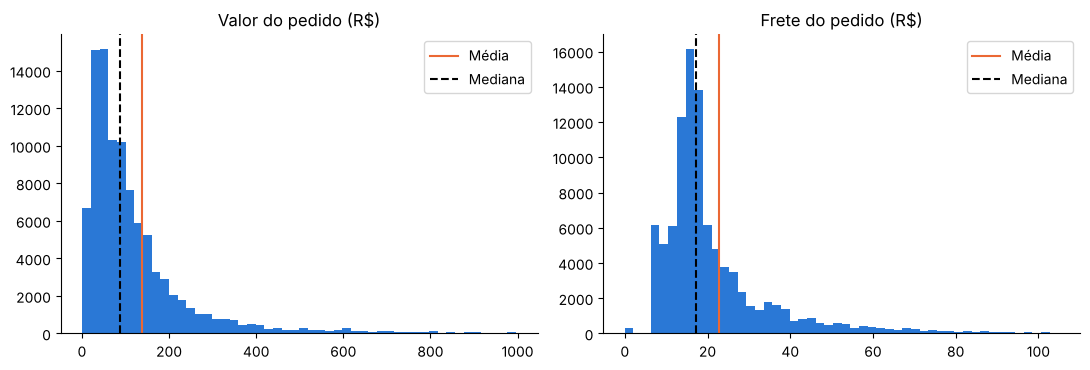

In [7]:
# Histogramas do valor e do frete, com a média e a mediana marcadas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

# Cortamos no percentil 99 só para o gráfico ficar legível
valor = vendas['receita'][vendas['receita'] < vendas['receita'].quantile(0.99)]
ax1.hist(valor, bins=50, color=AZUL)
ax1.axvline(vendas['receita'].mean(), color=LARANJA, label='Média')
ax1.axvline(vendas['receita'].median(), color='black', linestyle='--', label='Mediana')
ax1.set_title('Valor do pedido (R$)')
ax1.legend()

frete = vendas['frete'][vendas['frete'] < vendas['frete'].quantile(0.99)]
ax2.hist(frete, bins=50, color=AZUL)
ax2.axvline(vendas['frete'].mean(), color=LARANJA, label='Média')
ax2.axvline(vendas['frete'].median(), color='black', linestyle='--', label='Mediana')
ax2.set_title('Frete do pedido (R$)')
ax2.legend()

plt.tight_layout()
plt.savefig('figuras/00_distribuicao_valores.png', dpi=150)
plt.show()

**Leitura:** a maioria dos pedidos é de valor baixo. A mediana fica em torno de R\$ 87, mas alguns pedidos bem caros puxam a média para cima, para cerca de R\$ 137. Os valores variam muito de um pedido para outro (coeficiente de variação acima de 100%), por isso, nas comparações, também usei a **mediana**, que sofre menos com esses valores extremos.

Os outliers são cerca de 8% dos pedidos. Mantive esses pedidos na análise, porque são vendas reais (como móveis e eletrônicos), e não erros nos dados.

## 3. KPIs do negócio

Escolhi os indicadores que ajudam a responder à pergunta do trabalho e defini uma meta para cada um, usando o modelo **SMART** (meta específica, que dá para medir, possível de alcançar, importante para o negócio e com prazo). As metas são uma proposta minha para o plano de ação, não vêm dos dados.

| KPI | Como calcula | Por que importa | Meta |
|---|---|---|---|
| Receita mensal | Soma das vendas no mês | Mostra se a empresa está crescendo | Voltar a crescer 3% ao mês até o fim de 2019 |
| Ticket médio | Receita ÷ nº de pedidos | Mostra se o cliente gasta mais por compra | Manter acima de R\$ 135 |
| Prazo de entrega | Média de dias entre a compra e a entrega | Mede a eficiência da entrega | Cair de 12,6 para 10 dias em 12 meses |
| Taxa de atraso | Pedidos atrasados ÷ pedidos entregues | É o que mais derruba a nota do cliente | Ficar abaixo de 5%, até na Black Friday |
| Nota média | Média das avaliações (1 a 5) | Mostra se o cliente está satisfeito | Chegar a 4,3 em 12 meses |
| Recompra | Clientes com 2 ou mais pedidos ÷ total de clientes | Mostra se o cliente volta | Dobrar de 3% para 6% em 12 meses |
| Frete / preço | Frete ÷ preço do produto | Mostra quanto o frete pesa para o cliente | Reduzir 5 pontos no Norte e no Nordeste |

In [8]:
# Pedidos entregues (com data de entrega preenchida)
entregues = pedidos[pedidos['order_status'] == 'delivered'].dropna(subset=['order_delivered_customer_date'])

# Prazo de entrega em dias e se atrasou
prazo = (entregues['order_delivered_customer_date'] - entregues['order_purchase_timestamp']).dt.total_seconds() / 86400
atrasou = entregues['order_delivered_customer_date'].dt.normalize() > entregues['order_estimated_delivery_date']

# Quantos pedidos cada cliente fez (para a recompra)
compras = pedidos_validos.merge(clientes, on='customer_id').groupby('customer_unique_id')['order_id'].nunique()

# Receita mensal de 2018
receita_mes_2018 = vendas[vendas['mes'] >= '2018-01'].groupby('mes')['receita'].sum()

print('KPIs atuais')
print(f'Receita total: R$ {vendas["receita"].sum() / 1e6:.2f} milhões')
print(f'Receita média mensal em 2018: R$ {receita_mes_2018.mean() / 1e3:.0f} mil')
print(f'Ticket médio: R$ {vendas["receita"].mean():.2f}')
print(f'Prazo médio de entrega: {prazo.mean():.1f} dias')
print(f'Taxa de atraso: {atrasou.mean() * 100:.1f}%')
print(f'Nota média: {avaliacoes["review_score"].mean():.2f}')
print(f'Taxa de recompra: {(compras > 1).mean() * 100:.1f}%')
print(f'Frete / preço (mediana): {(vendas["frete"] / vendas["receita"]).median() * 100:.1f}%')

KPIs atuais
Receita total: R$ 13.45 milhões
Receita média mensal em 2018: R$ 918 mil
Ticket médio: R$ 137.37
Prazo médio de entrega: 12.6 dias
Taxa de atraso: 6.8%
Nota média: 4.09
Taxa de recompra: 3.0%
Frete / preço (mediana): 22.4%


## 4. Crescimento e receita

Neste trabalho, **receita** é o valor dos produtos vendidos, sem contar o frete. Só entram os pedidos que não foram cancelados.

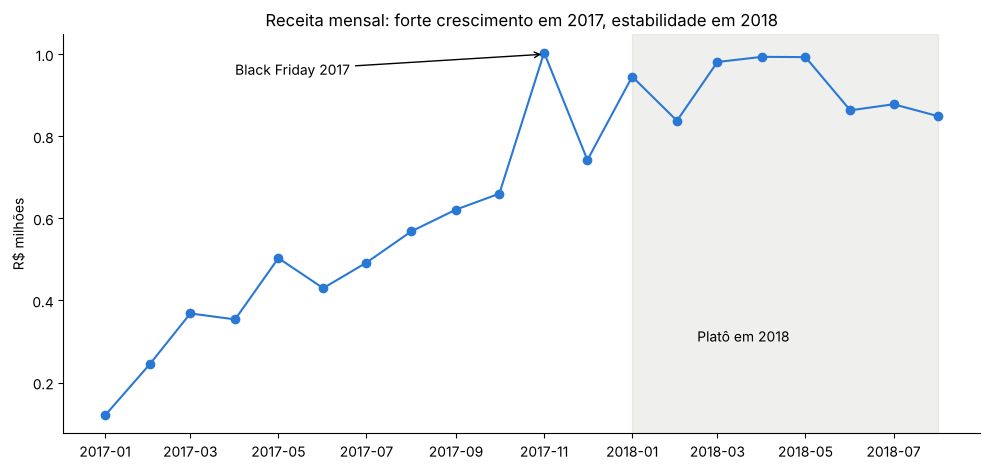

Jan–ago/2017: R$ 3.08 mi
Jan–ago/2018: R$ 7.34 mi
Crescimento: 138%
Ticket médio variou entre R$ 125 e R$ 153


In [9]:
# Receita e número de pedidos por mês
mensal = vendas.groupby('mes').agg(pedidos=('order_id', 'count'), receita=('receita', 'sum'))
mensal['ticket_medio'] = mensal['receita'] / mensal['pedidos']
meses = mensal.index.to_timestamp()

# Gráfico da receita mensal (em milhões de reais)
plt.plot(meses, mensal['receita'] / 1e6, color=AZUL, marker='o')
plt.axvspan(pd.Timestamp('2018-01-01'), meses.max(), color=CINZA, alpha=0.15)  # destaca 2018
plt.text(pd.Timestamp('2018-02-15'), 0.3, 'Platô em 2018')
plt.annotate('Black Friday 2017', xy=(pd.Timestamp('2017-11-01'), 1.0), xytext=(pd.Timestamp('2017-04-01'), 0.95),
             arrowprops=dict(arrowstyle='->'))
plt.title('Receita mensal: forte crescimento em 2017, estabilidade em 2018')
plt.ylabel('R$ milhões')
plt.tight_layout()
plt.savefig('figuras/01_receita_mensal.png', dpi=150)
plt.show()

# Comparação jan–ago de 2017 com jan–ago de 2018
receita_2017 = mensal.loc['2017-01':'2017-08', 'receita'].sum()
receita_2018 = mensal.loc['2018-01':'2018-08', 'receita'].sum()
print(f'Jan–ago/2017: R$ {receita_2017 / 1e6:.2f} mi')
print(f'Jan–ago/2018: R$ {receita_2018 / 1e6:.2f} mi')
print(f'Crescimento: {(receita_2018 / receita_2017 - 1) * 100:.0f}%')
print(f'Ticket médio variou entre R$ {mensal["ticket_medio"].min():.0f} e R$ {mensal["ticket_medio"].max():.0f}')

**Comparando com o mercado (dado externo):** segundo o relatório Webshoppers (Ebit/Nielsen), o e-commerce no Brasil faturou **R\$ 53,2 bilhões em 2018, 12% a mais que no ano anterior** ([fonte](https://www.tribunapr.com.br/noticias/economia/faturamento-do-e-commerce-soma-r-532-bilhoes-em-2018-alta-de-12/amp/)). No mesmo período, a Olist cresceu cerca de **138%**, bem mais rápido que o mercado.

**O que isso mostra:** a Olist cresceu porque vendeu **mais pedidos**, e não porque cada compra ficou mais cara (o ticket médio ficou parado perto de R\$ 137). Só que, desde janeiro de 2018, o número de pedidos parou de subir. Para voltar a crescer, a empresa vai precisar de algo novo.

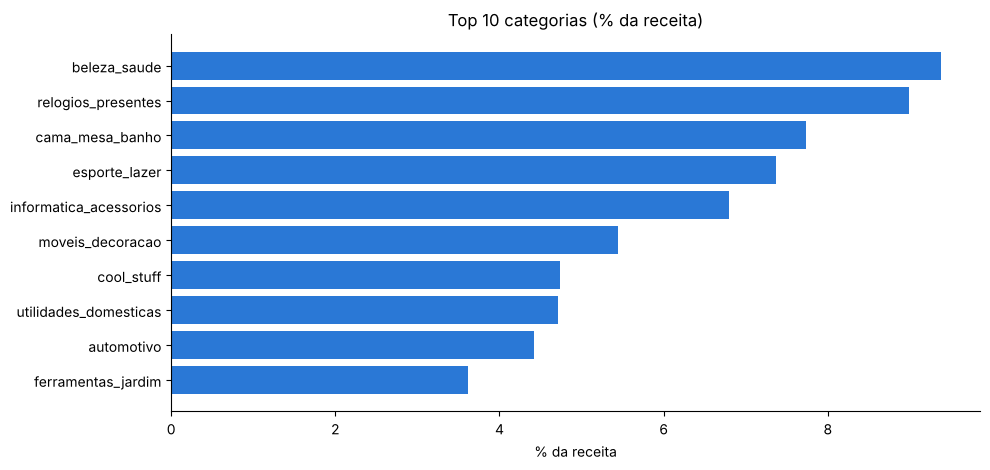

As 10 maiores categorias somam 63% da receita
Os 10% maiores vendedores fazem 67% da receita
60% dos vendedores estão em SP


In [10]:
# Receita por categoria de produto
itens_cat = itens.merge(produtos[['product_id', 'product_category_name']], on='product_id')
receita_cat = itens_cat.groupby('product_category_name')['price'].sum().sort_values(ascending=False)
participacao = receita_cat / receita_cat.sum() * 100

# Gráfico das 10 maiores categorias
top10 = participacao.head(10).sort_values()
plt.barh(top10.index, top10.values, color=AZUL)
plt.title('Top 10 categorias (% da receita)')
plt.xlabel('% da receita')
plt.tight_layout()
plt.savefig('figuras/02_categorias.png', dpi=150)
plt.show()

print(f'As 10 maiores categorias somam {participacao.head(10).sum():.0f}% da receita')

# Concentração dos vendedores: quanto os 10% maiores vendem
receita_vendedor = itens.groupby('seller_id')['price'].sum().sort_values(ascending=False)
qtd_top = int(len(receita_vendedor) * 0.10)
print(f'Os 10% maiores vendedores fazem {receita_vendedor.head(qtd_top).sum() / receita_vendedor.sum() * 100:.0f}% da receita')
print(f'{(vendedores["seller_state"] == "SP").mean() * 100:.0f}% dos vendedores estão em SP')

**Leitura:** as vendas estão bem divididas entre as categorias. Nenhuma passa de 10% da receita, então a empresa não depende de um único tipo de produto. Com os vendedores é diferente: só 10% deles fazem cerca de dois terços das vendas, e **60% estão em São Paulo**. Isso ajuda a entender o problema de entrega que aparece mais à frente: a maior parte dos produtos sai de SP.

## 5. Onde estão os clientes e quanto custa entregar para eles

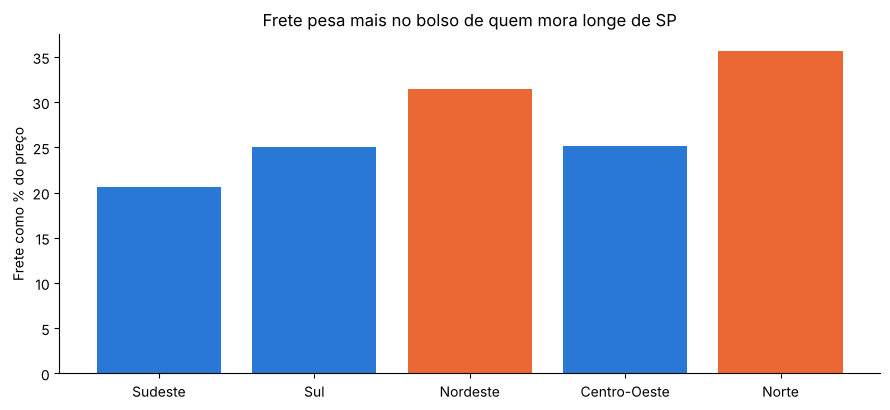

,pedidos,ticket_medio,frete_medio,frete_sobre_preco,pct_pedidos
regiao,,,,,
Sudeste,67146,131.0,19.9,20.6,68.6
Sul,13947,138.4,24.4,25.1,14.2
Nordeste,9272,165.2,35.9,31.5,9.5
Centro-Oeste,5712,150.5,26.5,25.1,5.8
Norte,1828,182.0,41.4,35.7,1.9


In [11]:
# Indicadores por região
vendas['frete_sobre_preco'] = vendas['frete'] / vendas['receita'] * 100

por_regiao = vendas.groupby('regiao').agg(
    pedidos=('order_id', 'count'),
    ticket_medio=('receita', 'mean'),
    frete_medio=('frete', 'mean'),
    frete_sobre_preco=('frete_sobre_preco', 'median'),
)
por_regiao['pct_pedidos'] = por_regiao['pedidos'] / por_regiao['pedidos'].sum() * 100
por_regiao = por_regiao.sort_values('pedidos', ascending=False)

# Gráfico: frete como % do preço, com Norte e Nordeste em laranja
cores = []
for regiao in por_regiao.index:
    if regiao in ['Norte', 'Nordeste']:
        cores.append(LARANJA)
    else:
        cores.append(AZUL)

plt.figure(figsize=(9, 4.2))
plt.bar(por_regiao.index, por_regiao['frete_sobre_preco'], color=cores)
plt.title('Frete pesa mais no bolso de quem mora longe de SP')
plt.ylabel('Frete como % do preço')
plt.tight_layout()
plt.savefig('figuras/03_frete_regiao.png', dpi=150)
plt.show()

por_regiao.round(1)

**Leitura:** a maior parte dos pedidos (69%) vem do Sudeste. No Norte, o frete custa cerca de **36% do preço do produto**, enquanto no Sudeste fica em 21%. E isso mesmo com o cliente do Norte comprando produtos mais caros. Ou seja, tem gente querendo comprar, mas o frete caro atrapalha a venda.

### Pedidos por 100 mil habitantes

Comparar só o total de pedidos de cada estado não seria justo, porque SP sozinho tem 22% da população do país. Então fiz igual à aula da dengue: dividi os pedidos pela população de cada estado e calculei quantos pedidos tem a cada 100 mil habitantes (população do IBGE, estimativa de 2016).

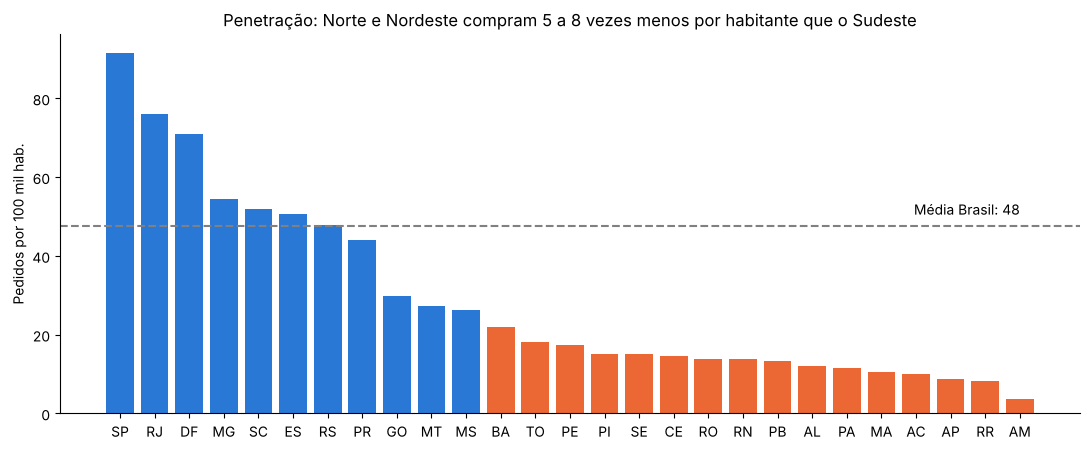

Pedidos por 100 mil habitantes, por região:
regiao
Sudeste         78.0
Sul             47.0
Centro-Oeste    36.0
Nordeste        16.0
Norte           10.0
dtype: float64


In [12]:
# População por estado - IBGE, estimativa de 1º/07/2016 (dado externo)
populacao = {
    'SP': 44749699, 'MG': 20997560, 'RJ': 16635996, 'BA': 15276566, 'RS': 11286500,
    'PR': 11242720, 'PE': 9410336, 'CE': 8963663, 'PA': 8272724, 'MA': 6954036,
    'SC': 6910553, 'GO': 6695855, 'AM': 4001667, 'PB': 3999415, 'ES': 3973697,
    'RN': 3474998, 'AL': 3358963, 'MT': 3305531, 'PI': 3212180, 'DF': 2977216,
    'MS': 2682386, 'SE': 2265779, 'RO': 1787279, 'TO': 1532902, 'AC': 816687,
    'AP': 782295, 'RR': 514229,
}

# Pedidos por 100 mil habitantes em cada estado
por_uf = vendas.groupby('customer_state')['order_id'].count().to_frame('pedidos')
por_uf['populacao'] = por_uf.index.map(populacao)
por_uf['pedidos_100mil'] = por_uf['pedidos'] / por_uf['populacao'] * 100000
por_uf = por_uf.sort_values('pedidos_100mil', ascending=False)

# Média do Brasil
media_brasil = por_uf['pedidos'].sum() / por_uf['populacao'].sum() * 100000

# Gráfico: Norte e Nordeste em laranja
cores = ['#eb6834' if REGIAO[uf] in ['Norte', 'Nordeste'] else '#2a78d6' for uf in por_uf.index]
plt.figure(figsize=(11, 4.6))
plt.bar(por_uf.index, por_uf['pedidos_100mil'], color=cores)
plt.axhline(media_brasil, color='gray', linestyle='--')
plt.text(len(por_uf) - 1, media_brasil + 3, f'Média Brasil: {media_brasil:.0f}', ha='right')
plt.title('Penetração: Norte e Nordeste compram 5 a 8 vezes menos por habitante que o Sudeste')
plt.ylabel('Pedidos por 100 mil hab.')
plt.tight_layout()
plt.savefig('figuras/03b_penetracao_uf.png', dpi=150)
plt.show()

# Mesmo cálculo por região
pop_regiao = pd.Series(populacao).groupby(REGIAO).sum()
pedidos_regiao = vendas.groupby('regiao')['order_id'].count()
print('Pedidos por 100 mil habitantes, por região:')
print((pedidos_regiao / pop_regiao * 100000).round(0).sort_values(ascending=False))

**Leitura:** São Paulo, Rio de Janeiro e Distrito Federal são os estados que mais compram por habitante. Já quase todo o Norte e o Nordeste ficam bem abaixo da média do país. Essas duas regiões têm **36% da população**, mas fazem só **11% dos pedidos**.

Se o Nordeste comprasse na mesma proporção que o Sul (47 pedidos por 100 mil habitantes, contra 16 hoje), seriam cerca de **900 pedidos a mais por mês**, uns 14% a mais do que a Olist vende hoje. **É a maior oportunidade de crescimento**, e o que trava é a entrega: demora e frete caro.

## 6. Entrega: prazo, promessa e atraso

Para cada pedido entregue, calculei duas coisas:
- **Prazo de entrega:** quantos dias levou da compra até chegar na casa do cliente.
- **Atraso:** se o pedido chegou depois da data que a Olist prometeu na hora da compra.

In [13]:
# Base de pedidos entregues
ent = pedidos[pedidos['order_status'] == 'delivered'].dropna(subset=['order_delivered_customer_date']).copy()

# Prazo real e prazo prometido, em dias
ent['prazo_dias'] = (ent['order_delivered_customer_date'] - ent['order_purchase_timestamp']).dt.total_seconds() / 86400
ent['prometido_dias'] = (ent['order_estimated_delivery_date'] - ent['order_purchase_timestamp']).dt.total_seconds() / 86400

# Dias de atraso (negativo = chegou antes) e se atrasou
ent['dias_atraso'] = (ent['order_delivered_customer_date'].dt.normalize() - ent['order_estimated_delivery_date']).dt.days
ent['atrasado'] = ent['dias_atraso'] > 0

# Tempo de cada etapa do processo
ent['aprovacao'] = (ent['order_approved_at'] - ent['order_purchase_timestamp']).dt.total_seconds() / 86400
ent['vendedor_posta'] = (ent['order_delivered_carrier_date'] - ent['order_approved_at']).dt.total_seconds() / 86400
ent['transporte'] = (ent['order_delivered_customer_date'] - ent['order_delivered_carrier_date']).dt.total_seconds() / 86400

# Nota da avaliação de cada pedido
nota = avaliacoes.groupby('order_id')['review_score'].mean()
ent = ent.merge(nota, on='order_id', how='left')

# Estado e região do cliente
ent = ent.merge(clientes, on='customer_id')
ent['regiao'] = ent['customer_state'].map(REGIAO)

print(f'Prazo médio de entrega: {ent["prazo_dias"].mean():.1f} dias (mediana {ent["prazo_dias"].median():.1f})')
print(f'Prazo médio prometido: {ent["prometido_dias"].mean():.1f} dias')
print(f'Pedidos com atraso: {ent["atrasado"].mean() * 100:.1f}%')
print()
print('Mediana de dias em cada etapa:')
print(ent[['aprovacao', 'vendedor_posta', 'transporte']].median().round(1))

Prazo médio de entrega: 12.6 dias (mediana 10.2)
Prazo médio prometido: 23.7 dias
Pedidos com atraso: 6.8%

Mediana de dias em cada etapa:
aprovacao         0.0
vendedor_posta    1.8
transporte        7.1
dtype: float64


                count  mean   std  min   25%   50%   75%    max
regiao                                                         
Centro-Oeste   5624.0  15.0   8.4  1.3   9.7  13.3  18.3  181.1
Nordeste       9044.0  20.0  12.3  0.9  12.9  17.3  24.0  194.9
Norte          1796.0  22.6  13.1  4.1  14.5  20.2  27.4  195.6
Sudeste       66193.0  10.8   8.5  0.5   5.8   8.7  13.2  209.6
Sul           13813.0  14.0   8.4  1.1   8.5  12.1  17.2  186.2


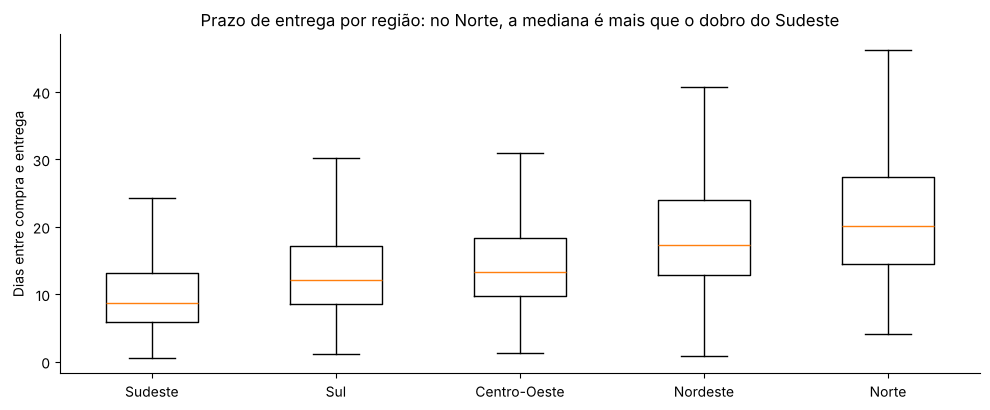

Outliers de prazo (acima de 29 dias): 5.1% dos pedidos


In [14]:
# Estatística descritiva do prazo por região
print(ent.groupby('regiao')['prazo_dias'].describe().round(1))

# Boxplot do prazo por região (sem mostrar os outliers, para ficar legível)
regioes = ['Sudeste', 'Sul', 'Centro-Oeste', 'Nordeste', 'Norte']
dados = [ent[ent['regiao'] == r]['prazo_dias'] for r in regioes]

plt.figure(figsize=(10, 4.2))
plt.boxplot(dados, showfliers=False)
plt.xticks([1, 2, 3, 4, 5], regioes)
plt.ylabel('Dias entre compra e entrega')
plt.title('Prazo de entrega por região: no Norte, a mediana é mais que o dobro do Sudeste')
plt.tight_layout()
plt.savefig('figuras/04b_boxplot_prazo_regiao.png', dpi=150)
plt.show()

# Outliers do prazo (método IQR)
q1 = ent['prazo_dias'].quantile(0.25)
q3 = ent['prazo_dias'].quantile(0.75)
limite = q3 + 1.5 * (q3 - q1)
print(f'Outliers de prazo (acima de {limite:.0f} dias): {(ent["prazo_dias"] > limite).mean() * 100:.1f}% dos pedidos')

**Leitura:** a Olist promete entregar, em média, em **24 dias**, mas entrega em **12**. Parece que ela promete um prazo bem longo para quase nunca atrasar. Isso ajuda a nota, mas um prazo grande na hora da compra pode assustar o cliente e fazer ele desistir. A etapa que mais demora é o **transporte** (cerca de 7 dias). O vendedor leva uns 2 dias para postar.

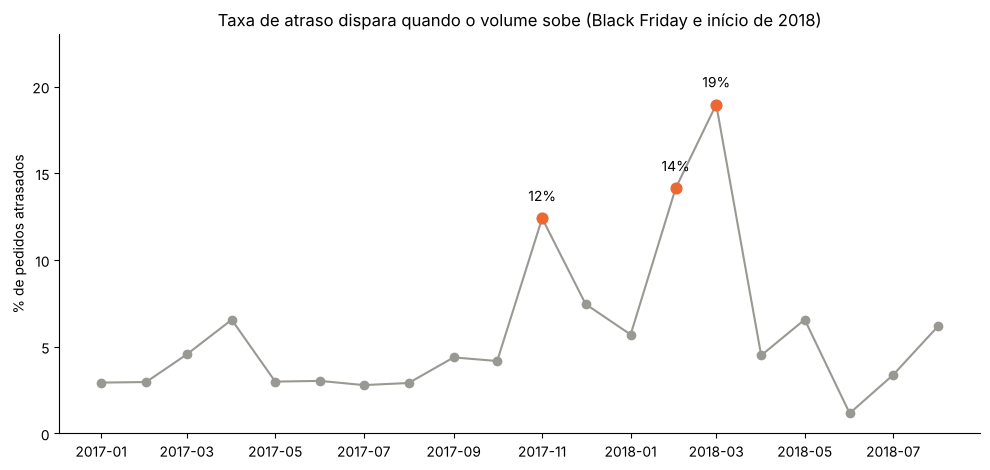

In [15]:
# Taxa de atraso por mês da compra
ent['mes'] = ent['order_purchase_timestamp'].dt.to_period('M')
periodo = ent[(ent['mes'] >= '2017-01') & (ent['mes'] <= '2018-08')]
atraso_mes = periodo.groupby('mes')['atrasado'].mean() * 100

plt.plot(atraso_mes.index.to_timestamp(), atraso_mes.values, color=CINZA, marker='o')

# Destaca os meses com mais de 10% de atraso
picos = atraso_mes[atraso_mes > 10]
plt.scatter(picos.index.to_timestamp(), picos.values, color=LARANJA, s=60, zorder=3)
for mes, valor in picos.items():
    plt.text(mes.to_timestamp(), valor + 1, f'{valor:.0f}%', ha='center')

plt.title('Taxa de atraso dispara quando o volume sobe (Black Friday e início de 2018)')
plt.ylabel('% de pedidos atrasados')
plt.ylim(0, 23)
plt.tight_layout()
plt.savefig('figuras/04_atraso_mensal.png', dpi=150)
plt.show()

**Leitura:** em um mês normal, só uns 4% a 6% dos pedidos atrasam. Mas na Black Friday de 2017 o atraso subiu para **12%**, e em fevereiro e março de 2018 chegou a **14% e 19%**, justamente quando as vendas aumentaram. **A entrega não conseguiu acompanhar o crescimento das vendas.**

## 7. Satisfação do cliente: o atraso é o que derruba a nota

faixa_atraso
>10 dias\nantes        4.32
1 a 10 dias\nantes     4.23
No dia                 4.04
Atraso\n1 a 5 dias     2.99
Atraso\n6 a 10 dias    1.77
Atraso\n>10 dias       1.71
Name: review_score, dtype: float64


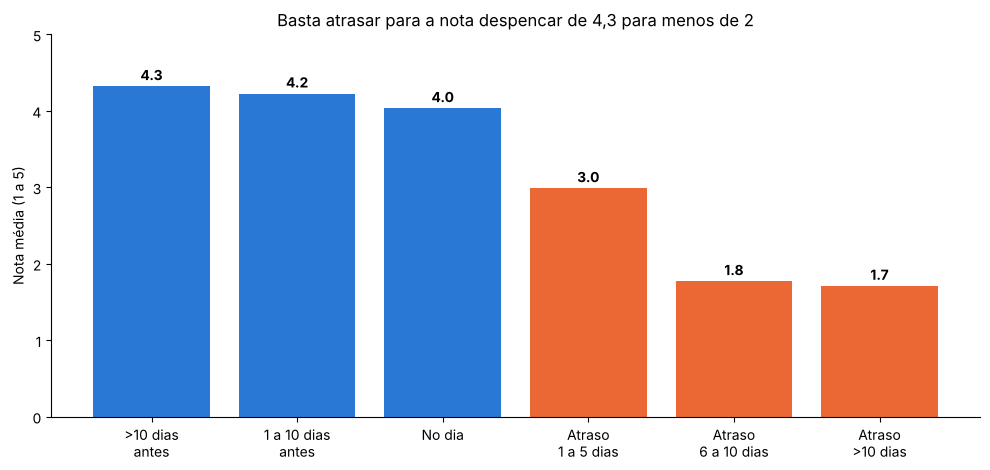

Nota média no prazo: 4.29
Nota média atrasado: 2.27
% de notas 1 ou 2 no prazo: 9%
% de notas 1 ou 2 atrasados: 61%
Correlação entre dias de atraso e nota: -0.27


In [16]:
# Agrupamos os pedidos por faixa de atraso
limites = [-999, -10, -1, 0, 5, 10, 999]
nomes = ['>10 dias\nantes', '1 a 10 dias\nantes', 'No dia', 'Atraso\n1 a 5 dias', 'Atraso\n6 a 10 dias', 'Atraso\n>10 dias']
ent['faixa_atraso'] = pd.cut(ent['dias_atraso'], bins=limites, labels=nomes)

nota_por_faixa = ent.groupby('faixa_atraso', observed=True)['review_score'].mean()
print(nota_por_faixa.round(2))

# Gráfico: azul para no prazo, laranja para atrasado
cores = [AZUL, AZUL, AZUL, LARANJA, LARANJA, LARANJA]
plt.bar(nota_por_faixa.index, nota_por_faixa.values, color=cores)
for i, valor in enumerate(nota_por_faixa.values):
    plt.text(i, valor + 0.08, f'{valor:.1f}', ha='center', fontweight='bold')
plt.ylim(0, 5)
plt.ylabel('Nota média (1 a 5)')
plt.title('Basta atrasar para a nota despencar de 4,3 para menos de 2')
plt.tight_layout()
plt.savefig('figuras/05_nota_por_atraso.png', dpi=150)
plt.show()

# Comparação direta: no prazo x atrasado
no_prazo = ent[ent['atrasado'] == False]
atrasados = ent[ent['atrasado'] == True]
print(f'Nota média no prazo: {no_prazo["review_score"].mean():.2f}')
print(f'Nota média atrasado: {atrasados["review_score"].mean():.2f}')
print(f'% de notas 1 ou 2 no prazo: {(no_prazo["review_score"] <= 2).mean() * 100:.0f}%')
print(f'% de notas 1 ou 2 atrasados: {(atrasados["review_score"] <= 2).mean() * 100:.0f}%')
print(f'Correlação entre dias de atraso e nota: {ent["dias_atraso"].corr(ent["review_score"]):.2f}')

**Leitura:** essa é a descoberta mais importante do trabalho. Quando o pedido chega no prazo, a nota fica acima de 4. Quando atrasa, a nota cai na hora. **6 em cada 10** pedidos atrasados recebem nota 1 ou 2, contra só 1 em cada 10 dos que chegam no prazo. Ou seja, para o cliente da Olist, ficar satisfeito depende basicamente de **receber no prazo**.

## 8. Mapa de desempenho por estado

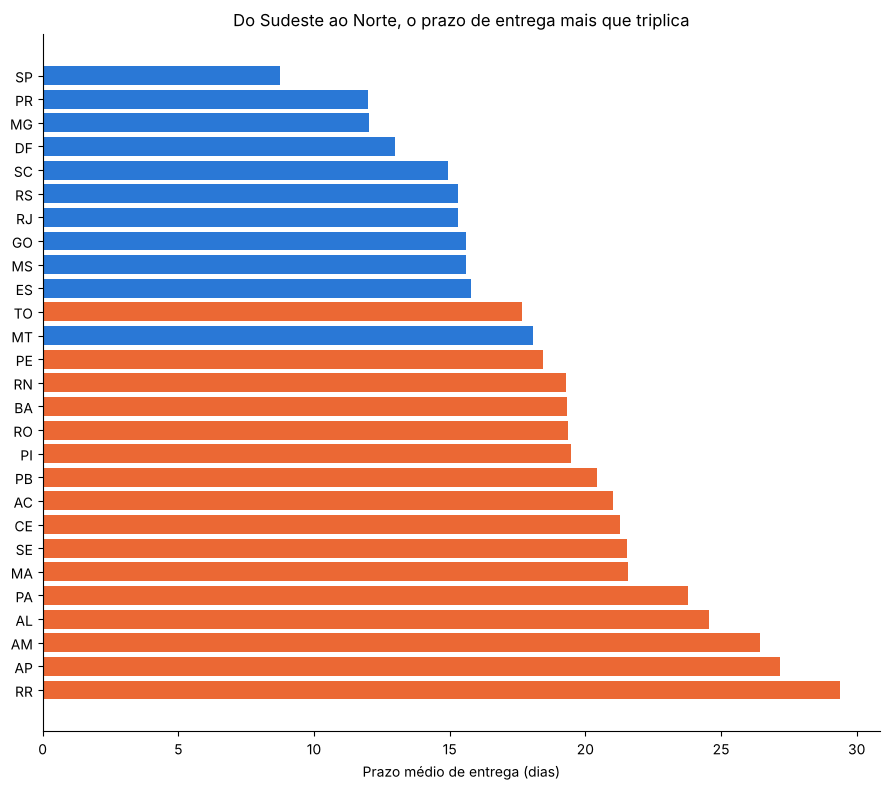

,pedidos,prazo_medio,pct_atraso,nota_media
customer_state,,,,
SP,40494,8.800000,4.500000,4.200000
PR,4923,12.000000,4.000000,4.200000
MG,11354,12.000000,4.600000,4.200000
DF,2080,13.000000,5.700000,4.100000
SC,3546,15.000000,8.200000,4.100000
RS,5344,15.300000,6.100000,4.200000
RJ,12350,15.300000,12.100000,4.000000
GO,1957,15.600000,6.500000,4.100000
MS,701,15.600000,9.700000,4.200000


In [17]:
# Indicadores de entrega por estado
por_estado = ent.groupby('customer_state').agg(
    pedidos=('order_id', 'count'),
    prazo_medio=('prazo_dias', 'mean'),
    pct_atraso=('atrasado', 'mean'),
    nota_media=('review_score', 'mean'),
)
por_estado['pct_atraso'] = por_estado['pct_atraso'] * 100
por_estado = por_estado.sort_values('prazo_medio')

# Gráfico de barras horizontais do prazo por estado
cores = [LARANJA if REGIAO[uf] in ['Norte', 'Nordeste'] else AZUL for uf in por_estado.index]
plt.figure(figsize=(9, 8))
plt.barh(por_estado.index, por_estado['prazo_medio'], color=cores)
plt.gca().invert_yaxis()
plt.xlabel('Prazo médio de entrega (dias)')
plt.title('Do Sudeste ao Norte, o prazo de entrega mais que triplica')
plt.tight_layout()
plt.savefig('figuras/06_prazo_por_uf.png', dpi=150)
plt.show()

# Tabela com cores (quanto mais escuro, pior o prazo e o atraso)
por_estado.round(1).style.background_gradient(subset=['prazo_medio', 'pct_atraso'], cmap='Oranges')

**Leitura:** em São Paulo, o pedido chega em **9 dias**. Em Roraima, Amapá e Amazonas, leva de **26 a 29 dias**. Os estados com a pior situação, que juntam entrega demorada, muito atraso e nota baixa, estão no **Nordeste**: Alagoas (21% dos pedidos atrasam), Maranhão (17%), Sergipe e Ceará (14% a 15%).

O **Rio de Janeiro** também chama atenção: é o segundo estado que mais compra, mas 12% dos pedidos atrasam e a nota fica abaixo de 4. Como o volume lá é grande, é a rota que mais vale a pena corrigir.

## 9. Recompra: o cliente compra uma vez e não volta

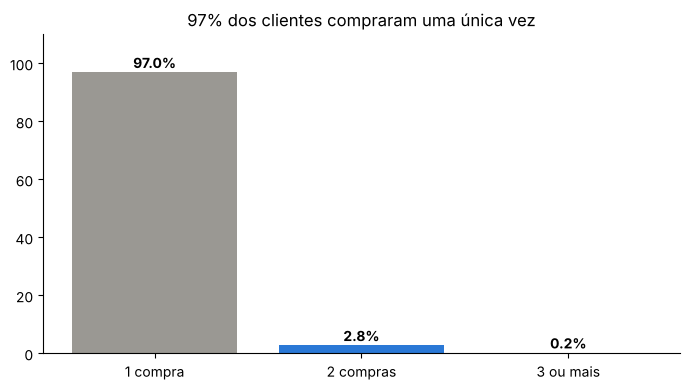

Clientes únicos: 94990
Voltaram a comprar: 3.0%

payment_type
credit_card    74.0
boleto         19.0
voucher         6.0
debit_card      1.0
not_defined     0.0
Name: proportion, dtype: float64
Parcelamento médio no cartão: 3.5 parcelas


In [18]:
# Quantos pedidos cada cliente fez (customer_unique_id identifica a pessoa)
pedidos_cliente = pedidos_validos.merge(clientes, on='customer_id')
compras_por_cliente = pedidos_cliente.groupby('customer_unique_id')['order_id'].nunique()

# Agrupamos em 1, 2 e 3 ou mais compras
uma = (compras_por_cliente == 1).mean() * 100
duas = (compras_por_cliente == 2).mean() * 100
tres_mais = (compras_por_cliente >= 3).mean() * 100

plt.figure(figsize=(7, 4))
plt.bar(['1 compra', '2 compras', '3 ou mais'], [uma, duas, tres_mais], color=[CINZA, AZUL, AZUL])
for i, valor in enumerate([uma, duas, tres_mais]):
    plt.text(i, valor + 1.5, f'{valor:.1f}%', ha='center', fontweight='bold')
plt.ylim(0, 110)
plt.title('97% dos clientes compraram uma única vez')
plt.tight_layout()
plt.savefig('figuras/07_recompra.png', dpi=150)
plt.show()

print('Clientes únicos:', len(compras_por_cliente))
print(f'Voltaram a comprar: {(compras_por_cliente > 1).mean() * 100:.1f}%')

# Formas de pagamento
print()
print(pagamentos['payment_type'].value_counts(normalize=True).round(2) * 100)
cartao = pagamentos[pagamentos['payment_type'] == 'credit_card']
print(f'Parcelamento médio no cartão: {cartao["payment_installments"].mean():.1f} parcelas')

**Leitura:** só **3%** dos clientes voltaram a comprar. Isso deixa o crescimento caro, porque cada nova venda depende de conquistar um cliente novo. Pelos dados, não parece haver nada que incentive o cliente a voltar depois da primeira compra. **É uma grande oportunidade de venda que ainda não está sendo aproveitada.**

*Sobre pagamento:* 74% dos pagamentos são no cartão de crédito, em média em 3,5 parcelas, e 19% no boleto.

## 10. Previsão de receita: set–dez/2018

**Como fiz a previsão:**
- **Ponto de partida:** a média de vendas por mês de março a agosto de 2018, já que as vendas ficaram estáveis nesse período.
- **Efeito das datas:** em 2017, novembro (Black Friday) vendeu 52% a mais que outubro, e dezembro vendeu 12% a mais. Usei esse mesmo aumento para prever novembro e dezembro de 2018.
- **Margem de erro:** somei e subtraí a variação normal de um mês para outro em 2018 (1 desvio-padrão).

*Limitação:* como os dados cobrem menos de 2 anos, é uma estimativa simples, não um modelo estatístico completo.

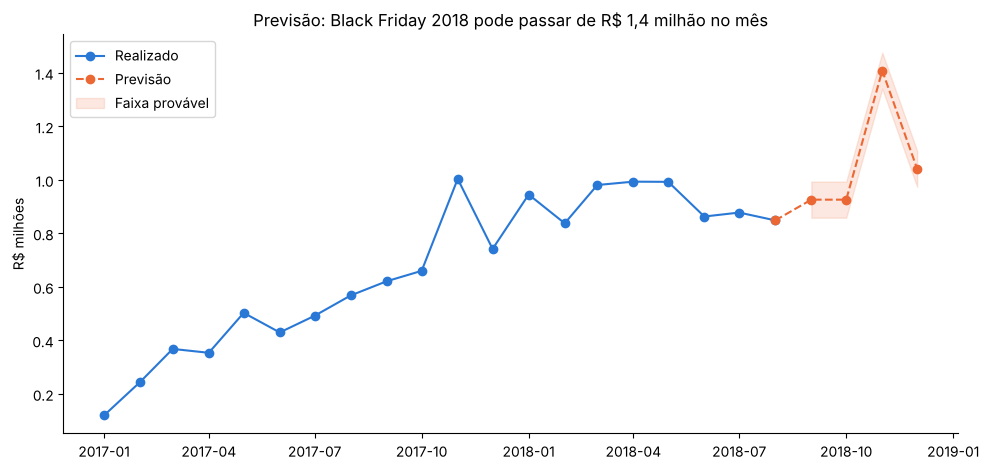

Efeito Black Friday: 1.52x | Dezembro: 1.12x
2018-09    0.93
2018-10    0.93
2018-11    1.41
2018-12    1.04
Freq: M, dtype: float64
Total previsto set–dez/2018: R$ 4.3 mi (faixa de R$ 4.0 a 4.6 mi)
Pedidos previstos em nov/2018: 10066 (recorde anterior: 7421)


In [19]:
# Base: média mensal de mar a ago/2018 (vendas estáveis no período)
base = mensal.loc['2018-03':'2018-08', 'receita'].mean()

# Variação normal de um mês para outro em 2018 (usada como margem de erro)
desvio = mensal.loc['2018-01':'2018-08', 'receita'].std()

# Efeito da Black Friday e do Natal, medido em 2017 (em relação a outubro)
efeito_nov = mensal.loc['2017-11', 'receita'] / mensal.loc['2017-10', 'receita']
efeito_dez = mensal.loc['2017-12', 'receita'] / mensal.loc['2017-10', 'receita']

# Previsão de set a dez/2018
meses_previstos = pd.period_range('2018-09', '2018-12', freq='M')
previsao = pd.Series([base, base, base * efeito_nov, base * efeito_dez], index=meses_previstos)

# Gráfico: realizado em azul, previsão em laranja tracejado com a faixa de incerteza
plt.plot(meses, mensal['receita'] / 1e6, color=AZUL, marker='o', label='Realizado')
x_prev = [meses[-1]] + list(meses_previstos.to_timestamp())
y_prev = [mensal['receita'].iloc[-1] / 1e6] + list(previsao / 1e6)
plt.plot(x_prev, y_prev, color=LARANJA, linestyle='--', marker='o', label='Previsão')
plt.fill_between(meses_previstos.to_timestamp(), (previsao - desvio) / 1e6, (previsao + desvio) / 1e6,
                 color=LARANJA, alpha=0.15, label='Faixa provável')
plt.ylabel('R$ milhões')
plt.title('Previsão: Black Friday 2018 pode passar de R$ 1,4 milhão no mês')
plt.legend()
plt.tight_layout()
plt.savefig('figuras/08_previsao.png', dpi=150)
plt.show()

print(f'Efeito Black Friday: {efeito_nov:.2f}x | Dezembro: {efeito_dez:.2f}x')
print((previsao / 1e6).round(2))
print(f'Total previsto set–dez/2018: R$ {previsao.sum() / 1e6:.1f} mi '
      f'(faixa de R$ {(previsao.sum() - 4 * desvio) / 1e6:.1f} a {(previsao.sum() + 4 * desvio) / 1e6:.1f} mi)')
pedidos_nov = mensal.loc['2018-03':'2018-08', 'pedidos'].mean() * efeito_nov
print(f'Pedidos previstos em nov/2018: {pedidos_nov:.0f} (recorde anterior: {mensal.loc["2017-11", "pedidos"]})')

**Leitura:** a previsão é de cerca de **R\$ 4,3 milhões** em vendas de setembro a dezembro de 2018, com uns **10 mil pedidos em novembro**. É mais do que o recorde de novembro de 2017, quando o atraso já tinha triplicado. **Se a Olist não reforçar a entrega antes da Black Friday, o problema pode se repetir ainda maior**, e as notas dos clientes caem junto.

## 11. Conclusões e recomendações

| # | O que descobri | O que recomendo | Resultado esperado |
|---|---|---|---|
| 1 | Quando atrasa, a nota cai de 4,3 para 2,3 | Preparar a entrega para os picos: contratar mais transportadoras e antecipar o estoque antes da Black Friday 2018 | Proteger a reputação no mês que mais vende (cerca de 10 mil pedidos) |
| 2 | No Norte e no Nordeste, a entrega demora o dobro e o frete é 50% a 70% mais caro | Ter centros de distribuição ou vendedores locais no Nordeste (ex.: Recife e Salvador) e baratear o frete nas rotas mais caras | Vender mais em regiões onde o cliente já gasta mais por compra |
| 3 | O Rio é o 2º estado que mais compra, mas 12% dos pedidos atrasam | Revisar a rota SP → RJ: renegociar ou trocar de transportadora | Melhora rápida num lugar com muitas vendas |
| 4 | A Olist promete 24 dias e entrega em 12 | Mostrar um prazo mais realista na hora da compra, de acordo com a região | Mais vendas sem aumentar o atraso |
| 5 | Só 3% dos clientes voltam | Criar um programa de recompra: cupom depois da entrega, cashback e lembretes por categoria | Cada 1 ponto a mais de recompra ≈ 950 clientes que voltam |
| 6 | 10% dos vendedores fazem cerca de 2/3 das vendas | Dar mais destaque nas buscas para vendedores com nota alta e que postam rápido | Incentivar os vendedores a entregar melhor |

### Mensagem final para o investidor
A Olist já mostrou que sabe atrair clientes: cresceu 138% enquanto o mercado cresceu 12%. Agora, o próximo passo é entregar bem e fazer o cliente voltar. Investir em entrega regional e em estrutura para os picos de venda é o que traz retorno mais rápido: melhora a nota, abre espaço no Norte e no Nordeste e prepara o terreno para a recompra.